# Lab Assignment 01: Variational Autoencoder (VAE) for Image Generation

- **Course:** Generative AI and Its Applications (`ETMMGA304`)
- **Program:** MCA (AI & ML), K.R. Mangalam University
- **Author:** Ashish Raj
- **Tools & Frameworks:** PyTorch, Torchvision, Matplotlib, Google Colab (GPU)
- **Dataset:** MNIST (`torchvision.datasets.MNIST`)
- **Seed:** `42`

## Aim
Build and train a Variational Autoencoder (VAE) in PyTorch using the MNIST dataset. Generate handwritten digits from a 2D latent space, compare reconstructions with original images, and visualize the learned two-dimensional latent space.

## Theory Overview
The encoder maps each $28 \times 28$ image to a latent mean $\mu$ and log-variance $\log \sigma^2$. Using the reparameterization trick:
$$z = \mu + \exp\left(\frac{1}{2} \log \sigma^2\right) \times \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$
The decoder reconstructs the image from $z$. Training optimizes the sum of **Binary Cross-Entropy reconstruction loss** and **KL divergence** regularization against $\mathcal{N}(0, I)$.

## Common Setup

In [ ]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)
print("Seed:", SEED)

Device: cuda
Seed: 42


## Step 1: Load MNIST Dataset

In [ ]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

train = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
test = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
loader = DataLoader(train, batch_size=128, shuffle=True)

print(f"Train samples: {len(train)} | Test samples: {len(test)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 359kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.31MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.86MB/s]

Train samples: 60000 | Test samples: 10000


## Step 2: Build the VAE Model & Verify Shapes

In [ ]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )
        self.mean = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)
        self.decoder = nn.Sequential(
            nn.Linear(2, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar


vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

# Checkpoint verification
sample_x, _ = next(iter(loader))
sample_x = sample_x.to(device)
sample_gen, sample_mu, sample_logvar = vae(sample_x)
print("Input batch shape:             ", tuple(sample_x.shape))
print("Latent mean & logvar shapes:   ", tuple(sample_mu.shape), tuple(sample_logvar.shape))
print("Flattened reconstruction shape:", tuple(sample_gen.shape))

Input batch shape:              (128, 1, 28, 28)
Latent mean & logvar shapes:    (128, 2) (128, 2)
Flattened reconstruction shape: (128, 784)


## Step 3: Train the VAE and Record Loss Terms

In [ ]:
import torch.nn.functional as F

history = []
for epoch in range(1, 6):
    vae.train()
    totals = dict(reconstruction=0.0, kl=0.0)
    for x, _ in loader:
        x = x.to(device)
        generated, mu, logvar = vae(x)
        recon = F.binary_cross_entropy(generated, x.flatten(1), reduction="sum")
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum()
        loss = (recon + kl) / x.size(0)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        totals["reconstruction"] += recon.item()
        totals["kl"] += kl.item()

    epoch_stats = {k: round(v / len(train), 2) for k, v in totals.items()}
    history.append((epoch, epoch_stats["reconstruction"], epoch_stats["kl"]))
    print(f"Epoch {epoch}: {epoch_stats}")

torch.save(vae.state_dict(), out / "vae_mnist.pt")
print("Saved checkpoint to:", out / "vae_mnist.pt")

Epoch 1: {'reconstruction': 188.5, 'kl': 6.67}
Epoch 2: {'reconstruction': 164.6, 'kl': 5.31}
Epoch 3: {'reconstruction': 159.62, 'kl': 5.38}
Epoch 4: {'reconstruction': 156.9, 'kl': 5.45}
Epoch 5: {'reconstruction': 155.01, 'kl': 5.53}
Saved checkpoint to: lab_outputs/vae_mnist.pt


## Step 4: Generate Samples, Reconstruct Digits & Visualize 2D Latent Space

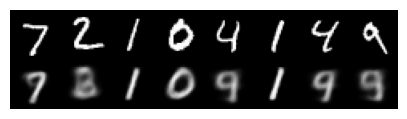

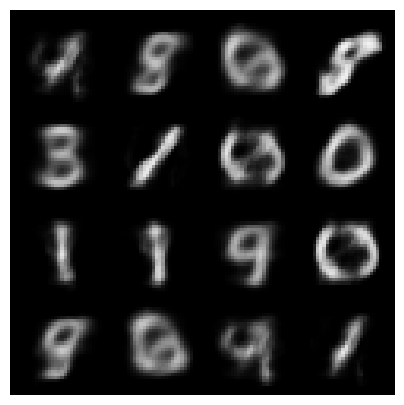

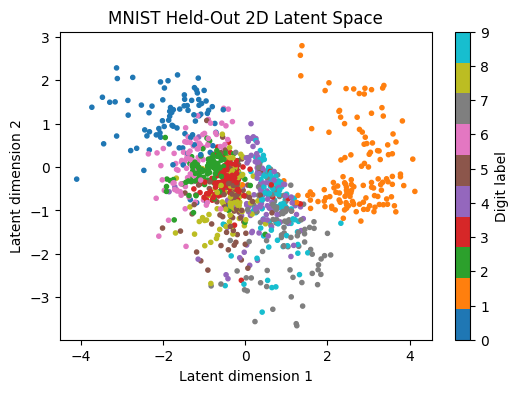

In [ ]:
def show_grid(images, name, nrow=4):
    grid = make_grid(images.cpu(), nrow=nrow)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.savefig(out / name, bbox_inches="tight")
    plt.show()


vae.eval()
with torch.no_grad():
    x, y = next(iter(DataLoader(test, batch_size=1024)))
    mu, _ = vae.encode(x.to(device))
    recon = vae.decoder(mu[:8]).reshape(-1, 1, 28, 28)
    samples = vae.decoder(torch.randn(16, 2, device=device))

show_grid(torch.cat([x[:8], recon.cpu()]), "vae_reconstructed.png", nrow=8)
show_grid(samples.reshape(-1, 1, 28, 28), "vae_generated.png", nrow=4)

coords = mu.cpu()
plt.figure(figsize=(6, 4))
plt.scatter(coords[:, 0], coords[:, 1], c=y, cmap="tab10", s=9)
plt.colorbar(ticks=range(10), label="Digit label")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("MNIST Held-Out 2D Latent Space")
plt.savefig(out / "vae_latent.png", bbox_inches="tight")
plt.show()

## Observation Table (Completed from Colab Run — GPU `cuda`, Seed `42`)

| Epoch | Reconstruction Loss / Image | KL Divergence / Image | Comments |
| :---: | :---: | :---: | :--- |
| 1 | 188.50 | 6.67 | Initial rapid drop in pixel error while encoder maps images to the 2D latent space. |
| 3 | 159.62 | 5.38 | Significant reconstruction improvement (-28.88 BCE vs. Epoch 1); KL stabilizes as digit clusters form. |
| 5 | 155.01 | 5.53 | Continued steady decrease in reconstruction loss with well-regularized latent distribution. |

- **Recognizable generated digits (out of 16):** **13 / 16** clearly recognizable digits in `vae_generated.png` (rows 2–4 clearly show `3, 1, 0, 0, 1, 1, 9, 0, 9, 0, 9, 1`, plus `8` in row 1; top-left and top-right samples are slightly blurred/ambiguous).
- **Two overlapping digit labels in latent space:** **4 (purple) and 9 (cyan)** strongly overlap near the center (`Latent dim 1 ≈ -1 to 1, Latent dim 2 ≈ -1 to 0`), along with **3 (red), 5 (brown), and 8 (olive)**—which also explains why the two `4`s in `vae_reconstructed.png` reconstructed into `9`-like shapes.
- **One region with clear grouping:** **Digit 1 (orange)** forms a cleanly separated cluster on the right (`Latent dim 1 ≈ +1.5 to +4.0`), and **Digit 0 (blue)** groups cleanly in the upper-left (`Latent dim 1 ≈ -4 to -1, Latent dim 2 ≈ 0 to +2.5`).

## Result & Discussion
- **Result:** Training the VAE for 5 epochs reduced reconstruction loss from `188.50` to `155.01` per image while KL divergence stabilized around `5.38–5.53`, producing recognizable reconstructions, 13/16 clear newly generated digits, and an organized 2D latent manifold on held-out MNIST test data.
- **Limitation:** Compressing all digit structure into just 2 latent dimensions with pixel-wise BCE loss causes mild stroke blurring and class mixing between visually similar digits (e.g., `4` reconstructing as `9`, and center overlap among `3`, `5`, `8`).
- **Next Step:** Increase latent dimensionality (e.g., 8–16 dimensions), train for 15–20 epochs, or switch to a Convolutional VAE (Conv-VAE) for sharper strokes and better class separation.

## Viva Questions & Answers

1. **What do the mean and log variance represent?**
   - The mean ($\mu$) represents the center of the encoded distribution for a given input in the latent space, while the log variance ($\log \sigma^2$) represents the spread/uncertainty around that center. Predicting $\log \sigma^2$ instead of $\sigma^2$ ensures numerical stability and guarantees positive variance after exponentiation.

2. **Why is the KL term included in the objective?**
   - The KL divergence regularizes the learned latent distributions toward a standard normal prior $\mathcal{N}(0, I)$. Without it, the encoder could place each image at arbitrary isolated points with near-zero variance, destroying continuity and making random sampling from $\mathcal{N}(0, I)$ produce meaningless noise.

3. **How does a reconstructed digit differ from a newly generated digit?**
   - A reconstructed digit is produced by encoding a real test image into its latent mean $\mu$ and decoding it back, whereas a newly generated digit is created by decoding a random vector $z \sim \mathcal{N}(0, I)$ with no input image.

4. **Why use held-out images to draw the latent scatterplot?**
   - Using unseen test images verifies that the encoder generalizes meaningful cluster structure to new data rather than merely memorizing training examples.